# Figure 16 — 3-regular graphs on the noiseless statevector simulator

Standalone QAOA vs qReduMIS powered by QAOA on random 3-regular graphs (20 seeds per size), for QAOA depths
$p = 2, \dots, 6$. QAOA angles are taken from [arXiv:2508.16309](https://arxiv.org/pdf/2508.16309)
(they depend on the average degree of the graph).

- **Fig. 16 (top)** (`figures/prob_3_regular_good_scaling.png`): success probability $P_{\mathrm{MIS}}$ vs number of nodes.
  qReduMIS reaches $P_{\mathrm{MIS}}=1$ for every $p$, so only $p=2$ is drawn.
- **Fig. 16 (bottom)** (`figures/quantum_calls_qredumis_3regular_good_scaling.png`): number of quantum calls made by qReduMIS.

In [1]:
%matplotlib inline
import sys, os
_REL_ROOT = os.getcwd() if os.path.isdir("consolidated_results") else os.path.abspath(os.pardir)  # release root (re-run safe)
sys.path.insert(0, _REL_ROOT)  # release root (for utils/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines

from utils.derived import DerivedData as _DerivedData

# Flat benchmark JSONs under data/data_3regular/results* were consolidated into
# consolidated_results/flat_json.csv; _D.json_frame(path) returns what pd.read_json(path) used to.
_D = _DerivedData()

BASE = _REL_ROOT  # release root
os.chdir(BASE)  # resolve relative paths from the release root

SAVE_FIGURES = False  # set False to skip saving figures
os.makedirs("figures", exist_ok=True)

DAYS = [11, 12, 13]
PS = [2, 3, 4, 5, 6]


def load_runs(method, p):
    """Concatenate the noiseless JSON results of `method` ('qaoa' or 'qredumis') for depth p."""
    return pd.concat(
        [_D.json_frame(f'data/data_3regular/results/benchmark_{method}_3regular_graphs_2025-09-{day}_p{p}.json')
         for day in DAYS],
        ignore_index=True)


In [2]:
## P_MIS per (N, seed) for qReduMIS = fraction of classical shots that return an MIS
def post_process_qredumis(df_qredumis):
    Ns = list(set(df_qredumis['N']))

    pmis_list=[]
    sizes=[]
    seeds=[]

    for N in Ns: 
        seeds_list=list(set(df_qredumis[(df_qredumis['N']==N)]['seed']))
        for seed in seeds_list:
            sub_df = df_qredumis[(df_qredumis['N']==N) & (df_qredumis['seed']==seed)]
            cshots = sub_df.shape[0]
            pmis = sub_df.apply(lambda row: row['baseline']==len(row['atom positions MIS']), axis=1).sum()/cshots
            pmis_list.append(pmis)
            sizes.append(N)
            seeds.append(seed)

    df_qredumis = pd.DataFrame()
    df_qredumis['N']=sizes
    df_qredumis['seed']= seeds
    df_qredumis['pmis']=pmis_list

    
    return df_qredumis


## Fig. 16 — success probability and quantum calls

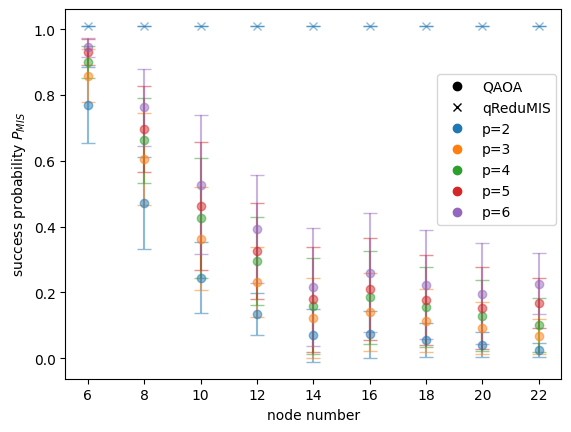

In [3]:
## Fig. 16 (top) -- P_MIS vs N; qReduMIS is drawn for p=2 only (it is 1 for every p, see below)
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Create a dictionary mapping each value of p to a default color
colors = {2: default_colors[0], 3: default_colors[1], 4: default_colors[2], 5: default_colors[3], 6: default_colors[4]}

offsets={2: 0.01, 
        3: 0.013,
        4: 0.016,
        5 : 0.019, 
        6 : 0.022}

plt.figure()
for p in [2,3,4,5,6]: ## for different number of layers
    ## standard qaoa
    sub_df = load_runs('qaoa', p)

    grouped = sub_df.groupby('N')['pmis'].agg(['mean', 'std']).reset_index()
    lower_bound = grouped['mean'] - grouped['std']
    upper_bound = grouped['mean'] + grouped['std']
    # Ensure no negative error bars
    yerr = np.where(lower_bound < 0, upper_bound - grouped['mean'], grouped['std'])
    plt.errorbar(grouped['N'], grouped['mean'], yerr=yerr, fmt='o', color=colors[p], capsize=5, alpha=0.5, label=f'p={p}')
   
## qredumis
p=2
sub_df = post_process_qredumis(load_runs('qredumis', p))

grouped = sub_df.groupby('N')['pmis'].agg(['mean', 'std']).reset_index()
lower_bound = grouped['mean'] - grouped['std']
upper_bound = grouped['mean'] + grouped['std']
# Ensure no negative error bars
yerr = np.where(lower_bound < 0, upper_bound - grouped['mean'], grouped['std'])
plt.errorbar(grouped['N'], grouped['mean']+ offsets[p], yerr=yerr, fmt='x', color=colors[p], capsize=5, alpha=0.5, label=f'p={p}')


plt.xlabel('node number')
plt.ylabel('success probability $P_{MIS}$')
plt.xticks(list(set(sub_df['N'])))
# Create custom legend handles
qaoa_handle = mlines.Line2D([], [], color='k', marker='o', linestyle='None', label='QAOA')
qredu_handle = mlines.Line2D([], [], color='k', marker='x', linestyle='None', label='qReduMIS')

# Add legend with custom handles
plt.legend(handles=[qaoa_handle, qredu_handle] + [mlines.Line2D([], [], color=colors[p], marker='o', linestyle='None', label=f'p={p}') for p in colors], loc='center', bbox_to_anchor=(0.87, 0.62))
if SAVE_FIGURES:
    plt.savefig("figures/prob_3_regular_good_scaling.png", format='png', dpi=300)
plt.show()


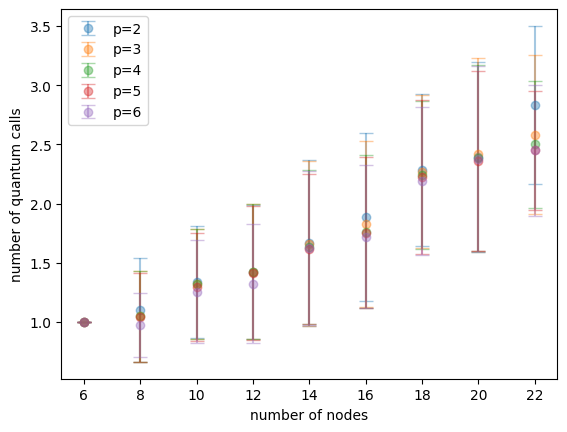

In [4]:
## Fig. 16 (bottom) -- number of quantum calls made by qReduMIS
plt.figure()
for p in [2,3,4,5,6]: ## for different number of layers
    sub_df = load_runs('qredumis', p)

    grouped = sub_df.groupby('N')['num iteration'].agg(['mean', 'std']).reset_index()
    lower_bound = grouped['mean'] - grouped['std']
    upper_bound = grouped['mean'] + grouped['std']
    # Ensure no negative error bars
    yerr = np.where(lower_bound < 0, upper_bound - grouped['mean'], grouped['std'])
    plt.errorbar(grouped['N'], grouped['mean'], yerr=yerr, fmt='o',color=colors[p], capsize=5, label=f'p={p}', alpha=0.4)


plt.xlabel('number of nodes')
plt.ylabel('number of quantum calls')
plt.xticks(list(set(sub_df['N'])))
plt.legend()
if SAVE_FIGURES:
    plt.savefig("figures/quantum_calls_qredumis_3regular_good_scaling.png", format='png', dpi=300)
plt.show()


In [5]:
## Numbers quoted in the text
for p in PS:
    qr = load_runs('qredumis', p)
    pm = post_process_qredumis(qr)
    print(f"p={p}: qReduMIS min P_MIS over all instances = {pm['pmis'].min():.3f};  "
          f"min quantum calls = {qr['num iteration'].min()}")

qaoa_p6 = load_runs('qaoa', 6)
print(f"\nStandalone QAOA, N=6, p=6: best P_MIS across seeds = {qaoa_p6[qaoa_p6['N'] == 6]['pmis'].max():.2f}")


p=2: qReduMIS min P_MIS over all instances = 1.000;  min quantum calls = 0
p=3: qReduMIS min P_MIS over all instances = 1.000;  min quantum calls = 0
p=4: qReduMIS min P_MIS over all instances = 1.000;  min quantum calls = 0
p=5: qReduMIS min P_MIS over all instances = 1.000;  min quantum calls = 0
p=6: qReduMIS min P_MIS over all instances = 1.000;  min quantum calls = 0

Standalone QAOA, N=6, p=6: best P_MIS across seeds = 0.96
